# ДЗ №2. Семантическая сегментация кожных поражений

**Источник данных:** [Dataset Ninja - Skin Cancer: HAM10000](https://datasetninja.com/skin-cancer-ham10000) (версия с масками Supervisely).

**Задача:** самостоятельно реализовать **одну** компактную архитектуру сегментации (encoder–decoder со skip-связью), обучить её как минимум **дважды** при изменении одного параметра и сравнить результаты.

В блокноте уже подготовлены чтение изображений и разметки, формирование фиксированных выборок, `Dataset`, `DataLoader` и визуальная проверка данных. **Реализацию архитектуры, обучение, вычисление метрики и экспериментальное сравнение выполняете самостоятельно.**

Полное условие и критерии: [страница домашнего задания](https://ai-mai-307.github.io/ml-dl-course-site/courses/deep-learning/2026-fall/assignments/hw-02/).

## 1. Скачивание и распаковка датасета

1. Откройте [Skin Cancer: HAM10000 - Dataset Ninja](https://datasetninja.com/skin-cancer-ham10000), выберите **Download** для **полного архива Supervisely** (около 2,6 ГБ). Обычный HAM10000 без аннотаций и **Download Sample** не подходят для итоговых экспериментов.
2. Распакуйте архив в каталог `data/` рядом с `solution.ipynb`. Пример из PowerShell в папке с ноутбуком:

   ```powershell
   New-Item -ItemType Directory -Force data
   tar -xf "ИМЯ_СКАЧАННОГО_АРХИВА.tar" -C data
   ```

   Не переименовывайте файлы внутри архива. Если после распаковки возникли дополнительные вложенные папки, изменять их структуру не нужно: следующий код рекурсивно найдёт `img/` и `ann/`.
3. Установите зависимости в используемое Python-окружение (если их ещё нет):

   ```powershell
   python -m pip install torch numpy pandas pillow matplotlib scikit-learn
   ```

Файл `dataset_meta_comp.csv` **не нужен**: таблица `ds_df` и разбиение создаются автоматически. При запуске Jupyter текущая рабочая папка должна совпадать с папкой, где лежат `solution.ipynb` и `data/`.

## 2. Импорт библиотек и фиксированные параметры

In [ ]:
import base64
import io
import json
import random
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset
import os

def set_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_random_seeds(SEED)

DATA_DIR = Path("data")
IMAGE_SIZE = (96, 128)       # (H, W); фиксируется для обоих экспериментов
MAX_TRAIN_PER_CLASS = 120    # фиксируется для обоих экспериментов
MAX_VAL_PER_CLASS = 30      # фиксируется для обоих экспериментов
BATCH_SIZE = 4              # одинаковый на CPU и GPU
NUM_WORKERS = 0             # без дополнительных процессов
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIN_EPOCHS = 8              # минимальное число эпох для КАЖДОГО запуска
M_MIN = 0.05               # минимальная val mIoU для базовой модели
MIN_TRAIN_LOSS_DROP = 0.20 # средний train loss: последние 3 эпохи против первых 3

print(f"PyTorch {torch.__version__} | Устройство: {DEVICE}")
print(f"Папка данных: {DATA_DIR.resolve()}")

PyTorch 2.14.1+cu130 | Устройство: cuda
Папка данных: C:\MAI\HW-02\data


## 3. Таблица изображений и метаданных

В архиве Dataset Ninja отсутствуют собственные `train/val`-метки и файл метаданных. Здесь мы находим JSON-аннотации в формате Supervisely, восстанавливаем имена файлов и список классов.

Два изображения без bitmap-разметки исключаются. Валидация построена как **воспроизводимое стратифицированное разбиение по классу изображения**.

In [ ]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка {DATA_DIR.resolve()}. Сначала распакуйте архив Dataset Ninja в data/."
    )

annotation_files = sorted(DATA_DIR.rglob("ann/*.json"))
if not annotation_files:
    raise FileNotFoundError(
        f"В {DATA_DIR.resolve()} не найдены ann/*.json. "
    )

rows = []
ignored_without_bitmap = 0
missing_images = []
for ann_path in annotation_files:
    with ann_path.open("r", encoding="utf-8") as f:
        ann = json.load(f)

    objects = [obj for obj in ann.get("objects", []) if obj.get("bitmap")]
    if not objects:
        ignored_without_bitmap += 1
        continue

    # Имена файлов Supervisely: ISIC_....jpg и ISIC_....jpg.json
    img_name = ann_path.name.removesuffix(".json")
    img_path = os.path.join(ann_path.parent.parent, "img", img_name)

    if not img_path.is_file():
        missing_images.append(str(img_path))
        continue

    class_titles = [obj["classTitle"] for obj in objects]
    class_name = Counter(class_titles).most_common(1)[0][0]
    rows.append({
        "img_name": img_name,
        "ann_name": ann_path.name,
        "class_name": class_name,
        "img_path": img_path,
        "ann_path": ann_path,
    })

if missing_images:
    raise FileNotFoundError(
        f"Для {len(missing_images)} аннотаций не найдены изображения. "
        f"Первое: {missing_images[0]}"
    )
if not rows:
    raise ValueError("Не найдено ни одного изображения с bitmap-аннотацией.")

ds_df = pd.DataFrame(rows).sort_values("img_name").reset_index(drop=True)

# Порядок по алфавиту соответствует исходной таблице преподавателя:
# 1=actinic keratoses, 2=basal cell carcinoma, 3=benign keratosis-like lesions,
# 4=dermatofibroma, 5=melanocytic nevi, 6=melanoma, 7=vascular lesions.
CLASS_NAMES = sorted(ds_df["class_name"].unique(), key=str.casefold)
CLASS_TO_INDEX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1  # ещё один класс - фон = 0

if NUM_CLASSES != 8:
    raise ValueError(
        f"Ожидались 7 диагностических классов и фон, получено: {CLASS_NAMES}. "
    )

ds_df["class_index"] = ds_df["class_name"].map(CLASS_TO_INDEX).astype(int)
print(f"Изображений с масками: {len(ds_df)}; без bitmap: {ignored_without_bitmap}")
print("Классы: 0 - фон")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} - {name}")
display(ds_df[["img_name", "class_name", "class_index"]].head())

Изображений с масками: 10013; без bitmap: 2
Классы: 0 — фон
  1 — actinic keratoses
  2 — basal cell carcinoma
  3 — benign keratosis-like lesions
  4 — dermatofibroma
  5 — melanocytic nevi
  6 — melanoma
  7 — vascular lesions


,img_name,class_name,class_index
0,ISIC_0024306.jpg,melanocytic nevi,5
1,ISIC_0024307.jpg,melanocytic nevi,5
2,ISIC_0024308.jpg,melanocytic nevi,5
3,ISIC_0024309.jpg,melanocytic nevi,5
4,ISIC_0024310.jpg,melanoma,6


In [4]:
train_df, val_df = train_test_split(
    ds_df,
    test_size=0.20,
    stratify=ds_df["class_index"],
    random_state=SEED,
)
train_df = train_df.copy().assign(split="train")
val_df = val_df.copy().assign(split="val")
ds_df = pd.concat([train_df, val_df], ignore_index=True)

assert set(train_df["img_path"]).isdisjoint(set(val_df["img_path"]))


def limit_per_class(frame, maximum):
    if maximum is None:
        return frame.sort_values("img_name").reset_index(drop=True)
    indices = []
    for _, group in frame.groupby("class_index"):
        n = min(len(group), maximum)
        indices.extend(group.sample(n=n, random_state=SEED).index.tolist())
    return frame.loc[indices].sort_values("img_name").reset_index(drop=True)


train_used = limit_per_class(train_df, MAX_TRAIN_PER_CLASS)
val_used = limit_per_class(val_df, MAX_VAL_PER_CLASS)
print(f"Train: {len(train_df)} всего, {len(train_used)} используются")
print(f"Val:   {len(val_df)} всего, {len(val_used)} используются")
print("Валидационные классы:", val_used["class_index"].value_counts().sort_index().to_dict())
assert val_used["class_index"].nunique() == NUM_CLASSES - 1, "В val представлены не все семь классов"
assert train_used["class_index"].nunique() == NUM_CLASSES - 1, "В train представлены не все семь классов"
assert set(train_used["img_path"]).isdisjoint(set(val_used["img_path"]))

Train: 8010 всего, 806 используются
Val:   2003 всего, 201 используются
Валидационные классы: {1: 30, 2: 30, 3: 30, 4: 23, 5: 30, 6: 30, 7: 28}


## 4. Преобразование Supervisely-масок и `Dataset`

Разметка хранится как `base64 → zlib → PNG` вместе со смещением `bitmap.origin`. Область объекта извлекается из **альфа-канала** PNG. Изображение масштабируется билинейно, маска - методом ближайшего соседа, чтобы индексы классов не смешивались.

`SkinCancerDataset[i]` возвращает тройку `(image, mask, class_index)`:

- `image`: `torch.float32`, форма `[3, H, W]`, нормировка в `[-1, 1]`;
- `mask`: `torch.int64`, форма `[H, W]`, метки `0..7` (`0` - фон);
- `class_index`: диагностический класс изображения (1–7).

Изображения и маски читаются **по требованию**: весь архив вряд ли поместится в оперативную память.

In [5]:
def decode_supervisely_bitmap_to_binary(mask_data_b64):
    raw = base64.b64decode(mask_data_b64)
    try:
        raw = zlib.decompress(raw)
    except zlib.error:
        # На случай, если данные уже содержат PNG без zlib-сжатия.
        pass
    with Image.open(io.BytesIO(raw)) as bitmap_image:
        rgba = np.asarray(bitmap_image.convert("RGBA"))
    return (rgba[..., 3] > 0).astype(np.uint8)


class SkinCancerDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size  # (H, W)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        h, w = self.image_size

        with Image.open(row["img_path"]) as img:
            img = img.convert("RGB")
            original_w, original_h = img.size
            img = img.resize((w, h), resample=Image.Resampling.BILINEAR)
            img_array = np.asarray(img).copy()

        image = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0
        image = (image - 0.5) / 0.5

        # Сначала маска в исходном разрешении, потом NEAREST-resize.
        full_mask = np.zeros((original_h, original_w), dtype=np.uint8)
        with Path(row["ann_path"]).open("r", encoding="utf-8") as f:
            annotation = json.load(f)

        for obj in annotation.get("objects", []):
            if not obj.get("bitmap"):
                continue
            class_title = obj["classTitle"]
            class_index = CLASS_TO_INDEX[class_title]
            bitmap = obj["bitmap"]
            small_mask = decode_supervisely_bitmap_to_binary(bitmap["data"])
            x0, y0 = map(int, bitmap["origin"])
            mh, mw = small_mask.shape

            x_start, y_start = max(0, x0), max(0, y0)
            x_end, y_end = min(original_w, x0 + mw), min(original_h, y0 + mh)
            if x_start >= x_end or y_start >= y_end:
                continue

            crop = small_mask[
                y_start - y0 : y_end - y0,
                x_start - x0 : x_end - x0,
            ]
            patch = full_mask[y_start:y_end, x_start:x_end]
            patch[crop > 0] = class_index

        mask_resized = Image.fromarray(full_mask).resize(
            (w, h), resample=Image.Resampling.NEAREST
        )
        mask = torch.from_numpy(np.asarray(mask_resized).copy()).long()
        return image, mask, int(row["class_index"])

## 5. `DataLoader` и проверка данных

В начале **каждого** обучения создавайте загрузчики заново через `make_dataloaders(SEED)` и вызывайте `set_random_seeds(SEED)` **перед созданием модели**. Это позволит корректно сравнить две конфигурации на одинаковом составе данных, с одинаковой инициализацией и порядком батчей.

Следующая ячейка проверяет тензоры одного батча и присутствие **всех семи классов в пиксельных масках `val`**. Проверка может занять некоторое время, так как разметка читается с диска.

In [6]:
train_dataset = SkinCancerDataset(train_used)
val_dataset = SkinCancerDataset(val_used)


def make_dataloaders(seed=SEED):
    train = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    val = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train, val


train_loader, val_loader = make_dataloaders()
images, masks, classes = next(iter(train_loader))
print("Изображения:", images.shape, images.dtype)
print("Маски:      ", masks.shape, masks.dtype)
print("Классы:    ", classes.tolist())
print("Метки масок:", torch.unique(masks).tolist())

assert images.shape[1:] == (3, *IMAGE_SIZE)
assert masks.shape[1:] == IMAGE_SIZE and masks.dtype == torch.int64
assert 0 <= masks.min().item() and masks.max().item() < NUM_CLASSES

val_pixel_classes = set()
for _, batch_masks, _ in val_loader:
    val_pixel_classes.update(torch.unique(batch_masks).tolist())

missing_classes = set(range(1, NUM_CLASSES)) - val_pixel_classes
print("Классы, присутствующие в val-масках:", sorted(val_pixel_classes))
assert not missing_classes, f"В пиксельных val-масках отсутствуют классы: {sorted(missing_classes)}"

Изображения: torch.Size([4, 3, 96, 128]) torch.float32
Маски:       torch.Size([4, 96, 128]) torch.int64
Классы:     [1, 2, 4, 6]
Метки масок: [0, 1, 2, 4, 6]
Классы, присутствующие в val-масках: [0, 1, 2, 3, 4, 5, 6, 7]


### Проверка соответствия изображения и маски

Ниже выводятся три изображения **разных диагностических классов**, соответствующие им маски и наложение. Визуально убедитесь, что разметка совпадает с областями поражений, и прокомментируйте замеченные особенности данных.

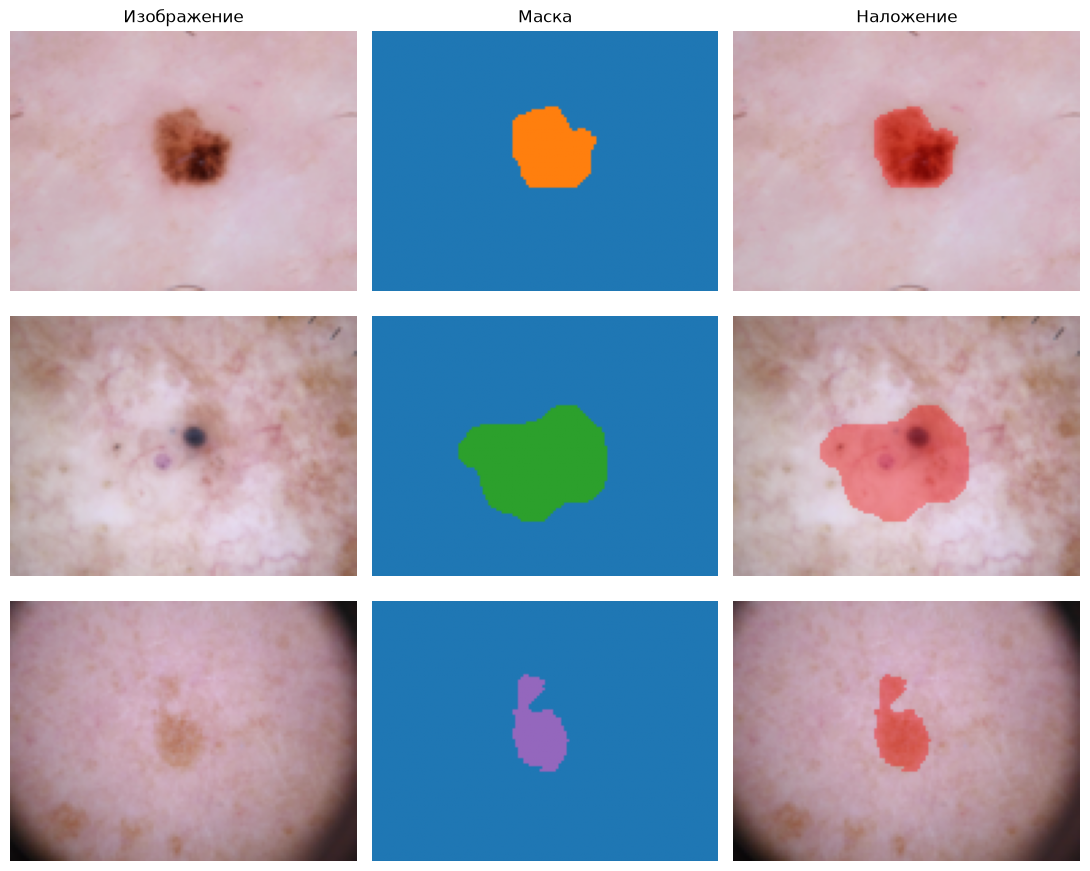

In [7]:
# Берём по одному примеру из трёх разных классов.
example_indices = [
    int(train_used.index[train_used["class_index"] == cls][0])
    for cls in sorted(train_used["class_index"].unique())[:3]
]

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11, 9))
for row_number, example_index in enumerate(example_indices):
    image, mask, class_ind = train_dataset[example_index]
    img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    overlay = img.copy()
    overlay[mask_np > 0] = (
        0.65 * overlay[mask_np > 0] + 0.35 * np.array([1.0, 0.0, 0.0])
    )
    axes[row_number, 0].imshow(img)
    axes[row_number, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row_number, 2].imshow(overlay)
    axes[row_number, 0].set_ylabel(f"Класс {class_ind}", rotation=90)
    for ax in axes[row_number]:
        ax.axis("off")

for ax, heading in zip(axes[0], ["Изображение", "Маска", "Наложение"]):
    ax.set_title(heading)
plt.tight_layout()
plt.show()

## 6. Самостоятельная реализация модели

**Реализуйте одну собственную компактную архитектуру `encoder–decoder` с хотя бы одной `skip`-связью**. Пользуйтесь базовыми слоями PyTorch (`torch.nn.Conv2d`, `MaxPool2d`, `ConvTranspose2d`, `BatchNorm2d` и т. п.). **Не используйте готовые модели** (`torchvision.models`, `timm`, `segmentation_models_pytorch` и аналоги) **или предобученные веса**.

Для входа `[B, 3, H, W]` выходом должны быть **логиты** `[B, 8, H, W]`. При `nn.CrossEntropyLoss` не вызывайте `softmax` до функции потерь. Кратко опишите выбранную архитектуру, в том числе skip-связь.

In [ ]:
def check_model_output_shape(model, example_batch, device=DEVICE):
    inputs = example_batch.to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
    expected = (inputs.shape[0], NUM_CLASSES, *inputs.shape[-2:])
    assert logits.shape == expected, (tuple(logits.shape), expected)
    assert logits.is_floating_point(), "Модель должна возвращать вещественные логиты"
    print("Размерность выхода корректна:", tuple(logits.shape))

#Реализована компактная свёрточная нейронная сеть с архитектурой encoder–decoder. 
# Энкодер состоит из двух уровней свёрток с уменьшением разрешения, а декодер восстанавливает пространственные размеры с помощью транспонированных свёрток. 
# Для сохранения деталей используются две skip-связи. 
# Выходной слой формирует логиты восьми классов для каждого пикселя изображения.

import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class MiniUNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        # Энкодер
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.pool = nn.MaxPool2d(2)

        # Самый глубокий уровень
        self.bottleneck = ConvBlock(32, 64)

        # Декодер
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(32, 16)

        # 8 выходных каналов: фон + 7 классов
        self.output = nn.Conv2d(16, num_classes, 1)

    def forward(self, x):
        # Извлечение признаков
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        b = self.bottleneck(self.pool(e2))

        # Восстановление с skip-связями
        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        # Возвращаем логиты без softmax
        return self.output(d1)


set_random_seeds(SEED)
model = MiniUNet(num_classes=NUM_CLASSES)

check_model_output_shape(model, images[:2])

params = sum(p.numel() for p in model.parameters())
print(f"Количество параметров: {params:,}")


Размерность выхода корректна: (2, 8, 96, 128)
Количество параметров: 117,800


## 7. Метрика: Mean Intersection over Union

Реализуйте расчёт mIoU по **семи классам поражений, исключая фон (класс 0)**:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \qquad
\mathrm{mIoU} = \frac{1}{7}\sum_{c=1}^{7}\mathrm{IoU}_c.
$$

**Сначала суммируйте** `TP`, `FP`, `FN` **по всей валидационной выборке**, затем вычисляйте IoU каждого класса. Не усредняйте IoU отдельных батчей. Вычисляйте индексы предсказанных классов через `argmax` по размерности каналов логитов. В блокноте выше проверено наличие пикселей всех семи классов в `val`.

Для самопроверки: если все пиксели предсказаны как фон, то `mIoU = 0`. Это **не считается успешным обучением**.

In [9]:

def update_confusion_matrix(confusion, logits, masks):
    predictions = logits.argmax(dim=1).reshape(-1).long()
    targets = masks.reshape(-1).long()

    valid = (targets >= 0) & (targets < NUM_CLASSES)

    indices = (
        targets[valid] * NUM_CLASSES + predictions[valid]
    )

    counts = torch.bincount(
        indices,
        minlength=NUM_CLASSES ** 2
    )

    confusion += counts.reshape(
        NUM_CLASSES, NUM_CLASSES
    ).cpu()


def compute_miou(confusion):
    confusion = confusion.double()

    tp = confusion.diag()[1:]
    fp = confusion.sum(dim=0)[1:] - tp
    fn = confusion.sum(dim=1)[1:] - tp

    denominator = tp + fp + fn

    assert torch.all(denominator > 0), (
        "В валидации отсутствуют некоторые классы"
    )

    iou = tp / denominator

    return iou.mean().item()


# Проверка правильности метрики
test_masks = torch.tensor([
    [[0, 1, 2, 3],
     [4, 5, 6, 7]]
])

perfect_logits = torch.nn.functional.one_hot(
    test_masks, num_classes=NUM_CLASSES
).permute(0, 3, 1, 2).float()

confusion = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES), dtype=torch.long
)

update_confusion_matrix(
    confusion, perfect_logits, test_masks
)

print("Идеальное предсказание:", compute_miou(confusion))

# Проверка случая, когда сеть предсказывает только фон
background_logits = torch.zeros_like(perfect_logits)
background_logits[:, 0] = 1

confusion.zero_()
update_confusion_matrix(
    confusion, background_logits, test_masks
)

print("Только фон:", compute_miou(confusion))


Идеальное предсказание: 1.0
Только фон: 0.0


## 8. Обучение базовой модели

Самостоятельно реализуйте цикл обучения и валидации. Необходимо:

- обучать с обновлением параметров (`zero_grad → backward → optimizer.step`);
- проверять модель в режиме `eval()` **без обновления весов**;
- сохранять за каждую эпоху `train loss`, `val loss` и **`val mIoU`**;
- провести **не менее 8 эпох**; средний `train loss` за **последние три** эпохи должен быть как минимум **на 20% ниже**, чем за **первые три**;
- получить `val mIoU ≥ 0.05` **для базовой модели** и показать маски, не сводящиеся к одному фону.

Как отправная точка подходят `torch.nn.CrossEntropyLoss()` и `torch.optim.Adam`, но гиперпараметры вы должны выбрать самостоятельно. Модель обязана обучаться даже при отсутствии GPU - уменьшать число изображений или обязательные эпохи нельзя.

**Перед созданием модели и загрузчиков:** повторно вызовите `set_random_seeds(SEED)` и `train_loader, val_loader = make_dataloaders(SEED)`.

In [ ]:

from time import perf_counter

EPOCHS = 30
BASELINE_LR = 0.001

CLASS_WEIGHTS = [0.1] + [1.0] * (NUM_CLASSES - 1)


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    total_loss = 0.0
    total_images = 0

    for images, masks, _ in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    return total_loss / total_images


@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_images = 0

    confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES), dtype=torch.long
    )

    foreground_pixels = 0
    all_pixels = 0

    for images, masks, _ in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, masks)

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

        update_confusion_matrix(confusion, logits, masks)

        predictions = logits.argmax(dim=1)
        foreground_pixels += (predictions != 0).sum().item()
        all_pixels += predictions.numel()

    val_loss = total_loss / total_images
    val_miou = compute_miou(confusion)
    foreground_percent = 100 * foreground_pixels / all_pixels

    return val_loss, val_miou, foreground_percent


def run_training(learning_rate, epochs=EPOCHS):
    # Одинаковая инициализация для обоих экспериментов
    set_random_seeds(SEED)

    train_dl, val_dl = make_dataloaders(SEED)

    network = MiniUNet(num_classes=NUM_CLASSES).to(DEVICE)

    weights = torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE)

    criterion = nn.CrossEntropyLoss(weight=weights)

    optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_miou": [],
        "val_foreground_percent": [],
    }

    start_time = perf_counter()

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(network, train_dl, criterion, optimizer)

        val_loss, val_miou, fg_percent = validate_one_epoch(network, val_dl, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_miou"].append(val_miou)
        history["val_foreground_percent"].append(fg_percent)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val mIoU: {val_miou:.4f} | "
            f"Foreground: {fg_percent:.1f}%",
            flush=True
        )

    elapsed = perf_counter() - start_time
    print(f"\nВремя обучения: {elapsed:.1f} секунд")

    return network, history


# Первое обучение - Baseline
model_baseline, history_baseline = run_training(
    learning_rate=BASELINE_LR,
    epochs=EPOCHS
)

# Проверка требований преподавателя
first_three = np.mean(history_baseline["train_loss"][:3])
last_three = np.mean(history_baseline["train_loss"][-3:])

loss_drop = (first_three - last_three) / first_three
best_miou = max(history_baseline["val_miou"])

print("\nИТОГИ BASELINE")
print(f"Эпох: {len(history_baseline['train_loss'])}")
print(f"Снижение train loss: {loss_drop:.1%}")
print(f"Лучшая val mIoU: {best_miou:.4f}")

print("Условие снижения loss:",
      "ВЫПОЛНЕНО" if loss_drop >= 0.20 else "НЕ ВЫПОЛНЕНО")

print("Условие mIoU >= 0.05:",
      "ВЫПОЛНЕНО" if best_miou >= M_MIN else "НЕ ВЫПОЛНЕНО")


Epoch 01/30 | Train loss: 1.9044 | Val loss: 1.7836 | Val mIoU: 0.0844 | Foreground: 48.0%
Epoch 02/30 | Train loss: 1.7440 | Val loss: 1.6670 | Val mIoU: 0.1148 | Foreground: 33.6%
Epoch 03/30 | Train loss: 1.6777 | Val loss: 1.5803 | Val mIoU: 0.1448 | Foreground: 34.0%
Epoch 04/30 | Train loss: 1.6343 | Val loss: 1.5535 | Val mIoU: 0.1389 | Foreground: 35.8%
Epoch 05/30 | Train loss: 1.6094 | Val loss: 1.5843 | Val mIoU: 0.1315 | Foreground: 49.4%
Epoch 06/30 | Train loss: 1.5810 | Val loss: 1.4891 | Val mIoU: 0.1617 | Foreground: 40.7%
Epoch 07/30 | Train loss: 1.5544 | Val loss: 1.5289 | Val mIoU: 0.1289 | Foreground: 37.9%
Epoch 08/30 | Train loss: 1.5541 | Val loss: 1.5051 | Val mIoU: 0.1490 | Foreground: 34.5%
Epoch 09/30 | Train loss: 1.5433 | Val loss: 1.4991 | Val mIoU: 0.1692 | Foreground: 37.4%
Epoch 10/30 | Train loss: 1.5366 | Val loss: 1.4885 | Val mIoU: 0.1668 | Foreground: 37.8%
Epoch 11/30 | Train loss: 1.5087 | Val loss: 1.4794 | Val mIoU: 0.1583 | Foreground: 33.4%

## 9. Один дополнительный эксперимент

**Заново обучите ту же архитектуру с той же начальной инициализацией**, изменив **один** фактор (например, функцию потерь, скорость обучения или аугментации). Обучайте не менее 8 эпох.

Состав `train/val`, размер изображений, `BATCH_SIZE`, `SEED` и условия сравнения должны совпадать. Для честного сравнения перед созданием второй модели и новых загрузчиков **снова** выполните `set_random_seeds(SEED)` и `make_dataloaders(SEED)`.

Улучшение `val mIoU` во втором запуске **не обязательно** - важны корректный эксперимент и содержательный вывод.

In [ ]:

# Контрольный эксперимент: меняем только learning rate

EXPERIMENT_LR = 0.0005

model_experiment, history_experiment = run_training(learning_rate=EXPERIMENT_LR, epochs=EPOCHS)

print("\nИТОГИ КОНТРОЛЬНОГО ЭКСПЕРИМЕНТА")
print(f"Эпох: {len(history_experiment['train_loss'])}")
print(f"Learning rate: {EXPERIMENT_LR}")
print(f"Лучшая val mIoU: {max(history_experiment['val_miou']):.4f}")
print(f"Финальная val mIoU: {history_experiment['val_miou'][-1]:.4f}")


Epoch 01/30 | Train loss: 1.9534 | Val loss: 1.7735 | Val mIoU: 0.1165 | Foreground: 50.0%
Epoch 02/30 | Train loss: 1.7829 | Val loss: 1.6932 | Val mIoU: 0.1235 | Foreground: 45.2%
Epoch 03/30 | Train loss: 1.6938 | Val loss: 1.6110 | Val mIoU: 0.1406 | Foreground: 36.1%
Epoch 04/30 | Train loss: 1.6425 | Val loss: 1.5555 | Val mIoU: 0.1709 | Foreground: 39.2%
Epoch 05/30 | Train loss: 1.6032 | Val loss: 1.5431 | Val mIoU: 0.1554 | Foreground: 48.1%
Epoch 06/30 | Train loss: 1.5754 | Val loss: 1.4940 | Val mIoU: 0.1607 | Foreground: 38.5%
Epoch 07/30 | Train loss: 1.5353 | Val loss: 1.5395 | Val mIoU: 0.1467 | Foreground: 33.4%
Epoch 08/30 | Train loss: 1.5386 | Val loss: 1.4852 | Val mIoU: 0.1705 | Foreground: 33.8%
Epoch 09/30 | Train loss: 1.5264 | Val loss: 1.4533 | Val mIoU: 0.1887 | Foreground: 34.3%
Epoch 10/30 | Train loss: 1.5177 | Val loss: 1.4502 | Val mIoU: 0.1774 | Foreground: 33.7%
Epoch 11/30 | Train loss: 1.4782 | Val loss: 1.4858 | Val mIoU: 0.1731 | Foreground: 30.8%

## 10. Графики, визуализация и выводы

Необходимо предоставить:

1. Графики `train loss`, `val loss` и `val mIoU` по эпохам **для двух запусков**.
2. Для **трёх валидационных изображений**: фото, истинная маска, предсказанная маска базовой модели. Прокомментируйте хотя бы один пример ошибки.
3. **Таблицу результатов** с фактическим числом эпох, параметрами и итоговыми метриками двух экспериментов:

| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| Baseline | - | … | … | … | … | … |
| Эксперимент 2 | … | … | … | … | … | … |

Итоговый вывод: что именно изменили, как это повлияло на обучение/качество и какие ограничения выявлены. Сохраните результаты выполнения в ноутбуке, но **не добавляйте датасет и веса модели в репозиторий**.

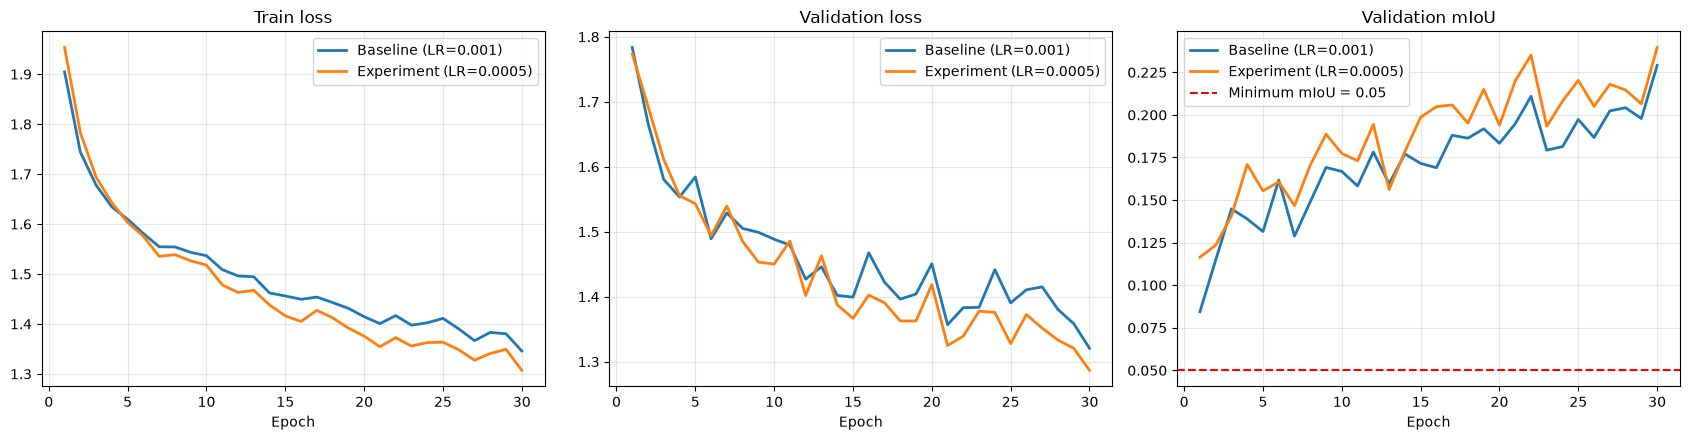

,Эксперимент,Learning rate,Эпохи,Train loss (финал),Val loss (финал),Val mIoU (финал),Лучшая mIoU,Снижение train loss (%)
0,Baseline,0.0010,30,1.3458,1.3207,0.2291,0.2291,22.8492
1,Experiment,0.0005,30,1.3071,1.2866,0.2396,0.2396,26.3908


Класс 1: ошибочных пикселей 18.3% | предсказанные классы: [0, 1, 2, 3, 4, 5, 6, 7]
Класс 3: ошибочных пикселей 35.6% | предсказанные классы: [0, 1, 2, 3]
Класс 6: ошибочных пикселей 66.0% | предсказанные классы: [0, 1, 3]


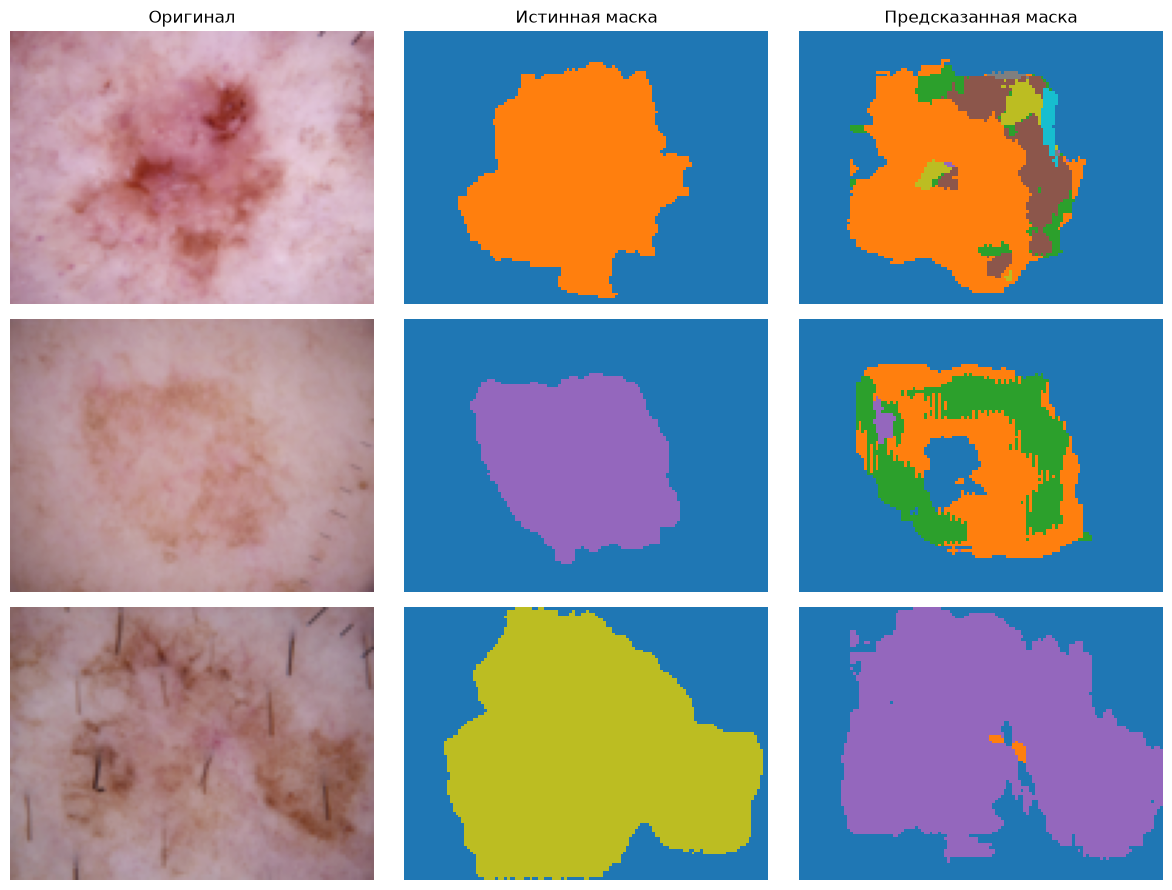

In [ ]:

# Сравнение результатов двух экспериментов

assert len(history_baseline["train_loss"]) == 30
assert len(history_experiment["train_loss"]) == 30

epochs = np.arange(1, 31)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

metrics = [
    ("train_loss", "Train loss"),
    ("val_loss", "Validation loss"),
    ("val_miou", "Validation mIoU"),
]

for ax, (key, title) in zip(axes, metrics):
    ax.plot(
        epochs, history_baseline[key],
        label="Baseline (LR=0.001)", linewidth=2
    )
    ax.plot(
        epochs, history_experiment[key],
        label="Experiment (LR=0.0005)", linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

axes[2].axhline(
    y=M_MIN, color="red", linestyle="--",
    label="Minimum mIoU = 0.05"
)
axes[2].legend()

plt.tight_layout()
plt.show()


# Итоговая сравнительная таблица

def summarize_run(name, lr, history):
    first = np.mean(history["train_loss"][:3])
    last = np.mean(history["train_loss"][-3:])

    return {
        "Эксперимент": name,
        "Learning rate": lr,
        "Эпохи": len(history["train_loss"]),
        "Train loss (финал)": history["train_loss"][-1],
        "Val loss (финал)": history["val_loss"][-1],
        "Val mIoU (финал)": history["val_miou"][-1],
        "Лучшая mIoU": max(history["val_miou"]),
        "Снижение train loss (%)": 100 * (first - last) / first,
    }


results_df = pd.DataFrame([
    summarize_run("Baseline", BASELINE_LR, history_baseline),
    summarize_run("Experiment", EXPERIMENT_LR, history_experiment),
])

display(results_df.round(4))


# Визуализация предсказаний базовой модели
# Используем только изображения из validation

model_baseline.eval()

# Выбираем три разных диагностических класса
selected_classes = [1, 3, 6]

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for row, class_id in enumerate(selected_classes):

    # Находим изображение нужного класса в val
    idx = int(
        val_dataset.frame.index[val_dataset.frame["class_index"] == class_id][0]
    )

    image, true_mask, real_class = val_dataset[idx]

    # Получаем предсказание обученной модели
    with torch.inference_mode():
        logits = model_baseline(image.unsqueeze(0).to(DEVICE))
        pred_mask = logits.argmax(dim=1)[0].cpu()

    # Возвращаем изображение в диапазон [0, 1]
    img = ((image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())

    true_np = true_mask.numpy()
    pred_np = pred_mask.numpy()

    # Исходная фотография
    axes[row, 0].imshow(img)

    # Настоящая маска
    axes[row, 1].imshow(
        true_np,
        cmap="tab10",
        vmin=0,
        vmax=NUM_CLASSES - 1,
        interpolation="nearest"
    )

    # Предсказанная маска
    axes[row, 2].imshow(
        pred_np,
        cmap="tab10",
        vmin=0,
        vmax=NUM_CLASSES - 1,
        interpolation="nearest"
    )

    axes[row, 0].set_ylabel(f"Класс {real_class}")

    for ax in axes[row]:
        ax.axis("off")

    # Доля пикселей с неправильной классификацией
    error_percent = 100 * np.mean(true_np != pred_np)

    print(
        f"Класс {real_class}: "
        f"ошибочных пикселей {error_percent:.1f}% | "
        f"предсказанные классы: {np.unique(pred_np).tolist()}"
    )

for ax, title in zip(
    axes[0], ["Оригинал", "Истинная маска", "Предсказанная маска"]):
    ax.set_title(title)

plt.tight_layout()
plt.show()


## Итоговые выводы

В ходе выполнения домашнего задания была самостоятельно реализована компактная свёрточная нейронная сеть MiniUNet с архитектурой encoder–decoder и двумя skip-связями. Модель содержит 117 800 обучаемых параметров и предназначена для семантической сегментации восьми классов: фона и семи типов кожных поражений.

Для обучения использовался датасет HAM10000 с пиксельной разметкой Supervisely. Учебная выборка содержала 806 изображений, валидационная - 201 изображение. Размер изображений составлял 96 × 128 пикселей, batch size - 4, seed - 42.

Были проведены два эксперимента по 30 эпох с одинаковой архитектурой, разбиением данных, начальной инициализацией и взвешенной функцией потерь CrossEntropyLoss. Единственным изменяемым параметром являлся learning rate.

| Показатель | Базовая модель | Контрольный эксперимент |
|---|---:|---:|
| Learning rate | 0.001 | 0.0005 |
| Эпохи | 30 | 30 |
| Финальный train loss | 1.3458 | 1.3071 |
| Финальный val loss | 1.3207 | 1.2866 |
| Финальная val mIoU | 0.2291 | 0.2396 |
| Снижение train loss | 22.85% | 26.39% |

Оба эксперимента удовлетворили требованиям по минимальному качеству сегментации (mIoU ≥ 0.05). Базовая модель также выполнила требование снижения среднего train loss не менее чем на 20%.

Уменьшение learning rate с 0.001 до 0.0005 улучшило итоговую val mIoU с 0.2291 до 0.2396, что соответствует относительному приросту примерно на 4.6%. Таким образом, в проведённом эксперименте меньший шаг обучения оказался эффективнее.

Анализ предсказанных масок показал, что сеть способна выделять области кожных поражений, однако допускает ошибки определения диагностического класса и границ. Например, для изображения класса melanoma (6) доля неправильно классифицированных пикселей составила 66.0%, а сама модель предсказала только классы 0, 1 и 3.

Полученные результаты показывают, что самостоятельно реализованная компактная CNN способна обучаться задаче многоклассовой семантической сегментации без предобученных весов. При этом качество распознавания отдельных классов остаётся ограниченным. Для дальнейшего улучшения можно исследовать другие функции потерь, балансировку классов и архитектурные решения.